In [5]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices, tune_lam
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute_frlc import impute_slice_fgw_barycenter, align_by_rotation
from metrics import cluster_compute_ari_and_plot
from prepare_dorsal_midbrain import prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

import torch

# if torch.cuda.is_available():
#     from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
# else:
from objective import solve_V_all_slices


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load data. 

Change fname according to local directories. The data is downloaded from:
https://db.cngb.org/stomics/mosta/download/

The resulting adata_insamp is a list of adata objects containing spatial transcriptomics. pd_B is the reference matrix representing mean expression for cell types. 

In [2]:
fname = "../../../Data/MOSTA/Dorsal_midbrain_cell_bin.h5ad"

adata_insamp, pd_B = prepare_data(fname, threshold=1.25, return_sc=False, renormalize=False)

11851


# Run ATLIS. 

In [12]:
torch.manual_seed(0); torch.cuda.manual_seed_all(0)
V, pi, aux = solve_V_all_slices(
                        adata_insamp, pd_B,
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5,
                        random_state = 0
                    )

lambda used = 6.833872e+02 (auto)
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
mu used = 3.306780e+02 (auto)
iter    0  f=3.467673e+08  rel_drop=8.905e-04  mean step=7.46e-06
iter   31  f=3.463587e+08  rel_drop=9.617e-06  mean step=7.04e-06
stopped after iteration # 31
final spatial/data ratio  = 5.569225e-03
final temporal/data ratio = 7.168798e-03


In [13]:

import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_insamp),
            celltype_key="annotation",
            embedding_key="spatial",
            clustering="leiden",
            plot=False,
            auto_resolution=True,
            random_state = 0
)

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_insamp])
for i, adt in enumerate(adata_insamp):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))



clustering at resolution=0.01 has been done! Found 1 clusters.
clustering at resolution=1.2 has been done! Found 42 clusters.
clustering at resolution=0.605 has been done! Found 23 clusters.
clustering at resolution=0.3075 has been done! Found 15 clusters.
clustering at resolution=0.15875 has been done! Found 9 clusters.
clustering at resolution=0.233125 has been done! Found 14 clusters.
clustering at resolution=0.1959375 has been done! Found 10 clusters.
clustering at resolution=0.21453125 has been done! Found 11 clusters.
Leiden: target_k=11, best_resolution=0.215, n_clusters=11
ari=0.3345019337399608
nmi=0.3949359422846195


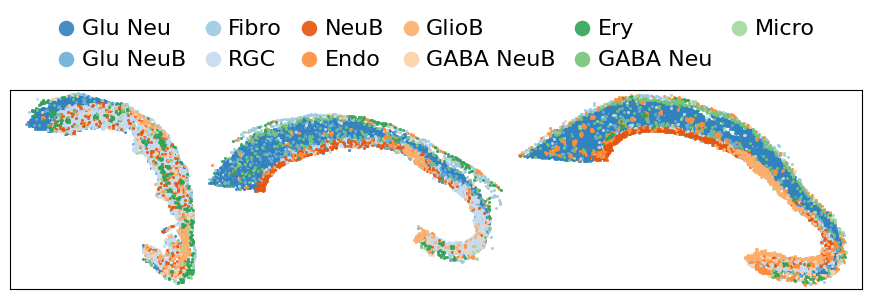

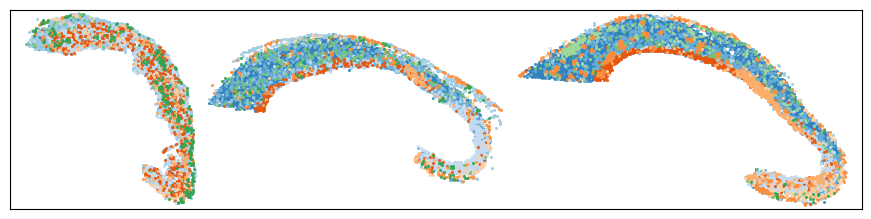

In [16]:
cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_insamp,
    obs_key="annotation",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 1050,
    s=5,
    legend_loc='upper center',
    legend_bbox=(0.5,0.8),
    legend_ncol = 6,
    legend_font=16,
    truth_key="pred_label",
    truth_cmap=cmap
)
plt.show()

fig, ax = plot_slices_horizontal_centered(
    adata_insamp,
    obs_key="pred_label",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 1050,
    s=5,
    legend=False,
    truth_key="pred_label",
    truth_cmap=cmap
)
plt.show()


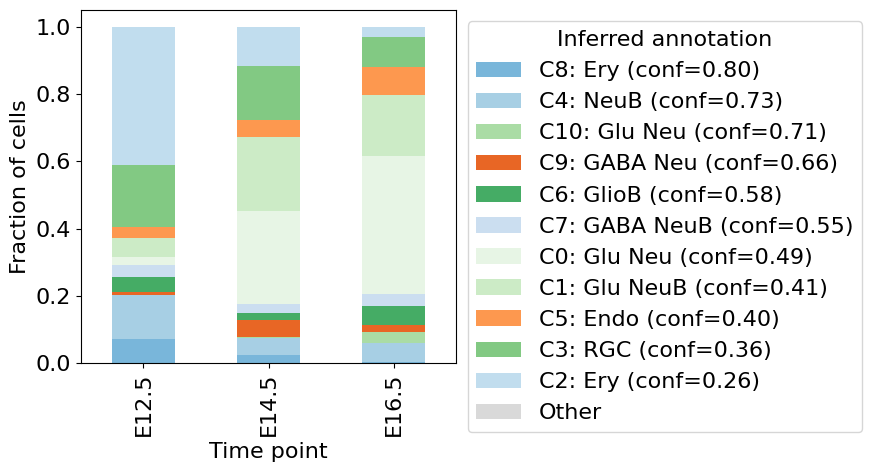

/tmp/ipykernel_1366797/1052660081.py:102: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([time_key, annotation_key])


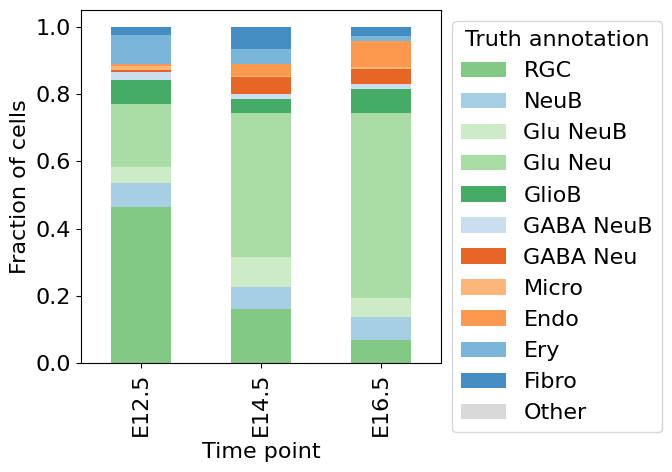

In [17]:
import re
import colorsys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from downstream import analyze_cluster_dynamics

bar_colors = {
    "RGC":       "#82c983",
    "NeuB":      "#a7cfe4",
    "Glu NeuB":  "#ccebc6",
    "Glu Neu":   "#aadca5",
    "GlioB":     "#45ac65",
    "GABA NeuB": "#cbdef0",
    "GABA Neu":  "#e86625",
    "Micro":     "#fdb679",
    "Endo":      "#fd984f",
    "Ery":       "#79b6da",
    "Fibro":     "#458ec3",
}
BAR_ORDER = list(bar_colors)
OTHER_COLOR = "#D9D9D9"


def base_type(label):
    s = re.sub(r"^C\d+:\s*", "", str(label))
    return re.sub(r"\s*\(conf=[\d.]+\)$", "", s).strip()


def shade(hex_color, k):
    if k == 0:
        return hex_color
    h, l, s = colorsys.rgb_to_hls(*mcolors.to_rgb(hex_color))
    return mcolors.to_hex(colorsys.hls_to_rgb(h, min(0.93, l + 0.18 * k), s))


def order_and_color(df, order=None, shade_repeats=True):
    if order is None:
        cols = [c for c in df.columns if c != "Other"]
        cols.sort(key=lambda c: (BAR_ORDER.index(base_type(c))
                                 if base_type(c) in BAR_ORDER else 999, str(c)))
    else:
        cols = [c for c in order if c in df.columns and c != "Other"]
        cols += [c for c in df.columns if c not in cols and c != "Other"]
    cols += [c for c in df.columns if c == "Other"]

    seen, colors = {}, []
    for c in cols:
        if c == "Other":
            colors.append(OTHER_COLOR)
            continue
        b = base_type(c)
        k = seen.get(b, 0) if shade_repeats else 0
        seen[b] = seen.get(b, 0) + 1
        colors.append(shade(bar_colors.get(b, "#999999"), k))
    return df[cols], colors

def sort_hpf_index(df):
    nums = df.index.astype(str).str.replace("E", "", regex=False).astype(float)
    return df.iloc[np.argsort(nums)]


# --- inferred clusters -------------------------------------------------
(cluster_time_df, cluster_celltype_df, cluster_label_df,
 cluster_time_counts, cluster_markers) = analyze_cluster_dynamics(
    adata_insamp, V, pd_B, cluster_key="pred_label", time_key="Time point")

cluster_to_label = {
    row.cluster: f"C{row.cluster}: {row.label} (conf={row.confidence:.2f})"
    for _, row in cluster_label_df.iterrows()
}

plot_df = cluster_time_counts.T.rename(columns=cluster_to_label)
plot_df = sort_hpf_index(plot_df)
plot_df = plot_df.div(plot_df.sum(axis=1), axis=0)

K = 12
conf = {cluster_to_label[r.cluster]: r.confidence for _, r in cluster_label_df.iterrows()}
top_types = (pd.Series(conf).reindex(plot_df.columns)
             .sort_values(ascending=False).head(K).index)

plot_df["Other"] = plot_df.drop(columns=top_types).sum(axis=1)
plot_df = plot_df[top_types.tolist() + ["Other"]]
plot_df, colors = order_and_color(plot_df, order=top_types.tolist())

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 16
ax = plot_df.plot(kind="bar", stacked=True, color=colors)
ax.set_ylabel("Fraction of cells")
ax.set_xlabel("Time point")
ax.legend(title="Inferred annotation", bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()
plt.show()


# --- ground-truth annotation ------------------------------------------
time_key, annotation_key = "Time point", "annotation"

ann_df = (
    pd.concat([a.obs[[time_key, annotation_key]] for a in adata_insamp], axis=0)
      .groupby([time_key, annotation_key])
      .size()
      .unstack(fill_value=0)
      .pipe(lambda x: x.div(x.sum(axis=1), axis=0))
)
ann_df = sort_hpf_index(ann_df)

K = 12
top = ann_df.mean(axis=0).sort_values(ascending=False).head(K).index
ann_df["Other"] = ann_df.drop(columns=top).sum(axis=1)
ann_df = ann_df[top.tolist() + ["Other"]]
ann_df, colors = order_and_color(ann_df)

plt.rcParams["figure.figsize"] = (7, 5)
ax = ann_df.plot(kind="bar", stacked=True, color=colors)
ax.set_ylabel("Fraction of cells")
ax.set_xlabel("Time point")
ax.legend(title="Truth annotation", bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()
plt.show()

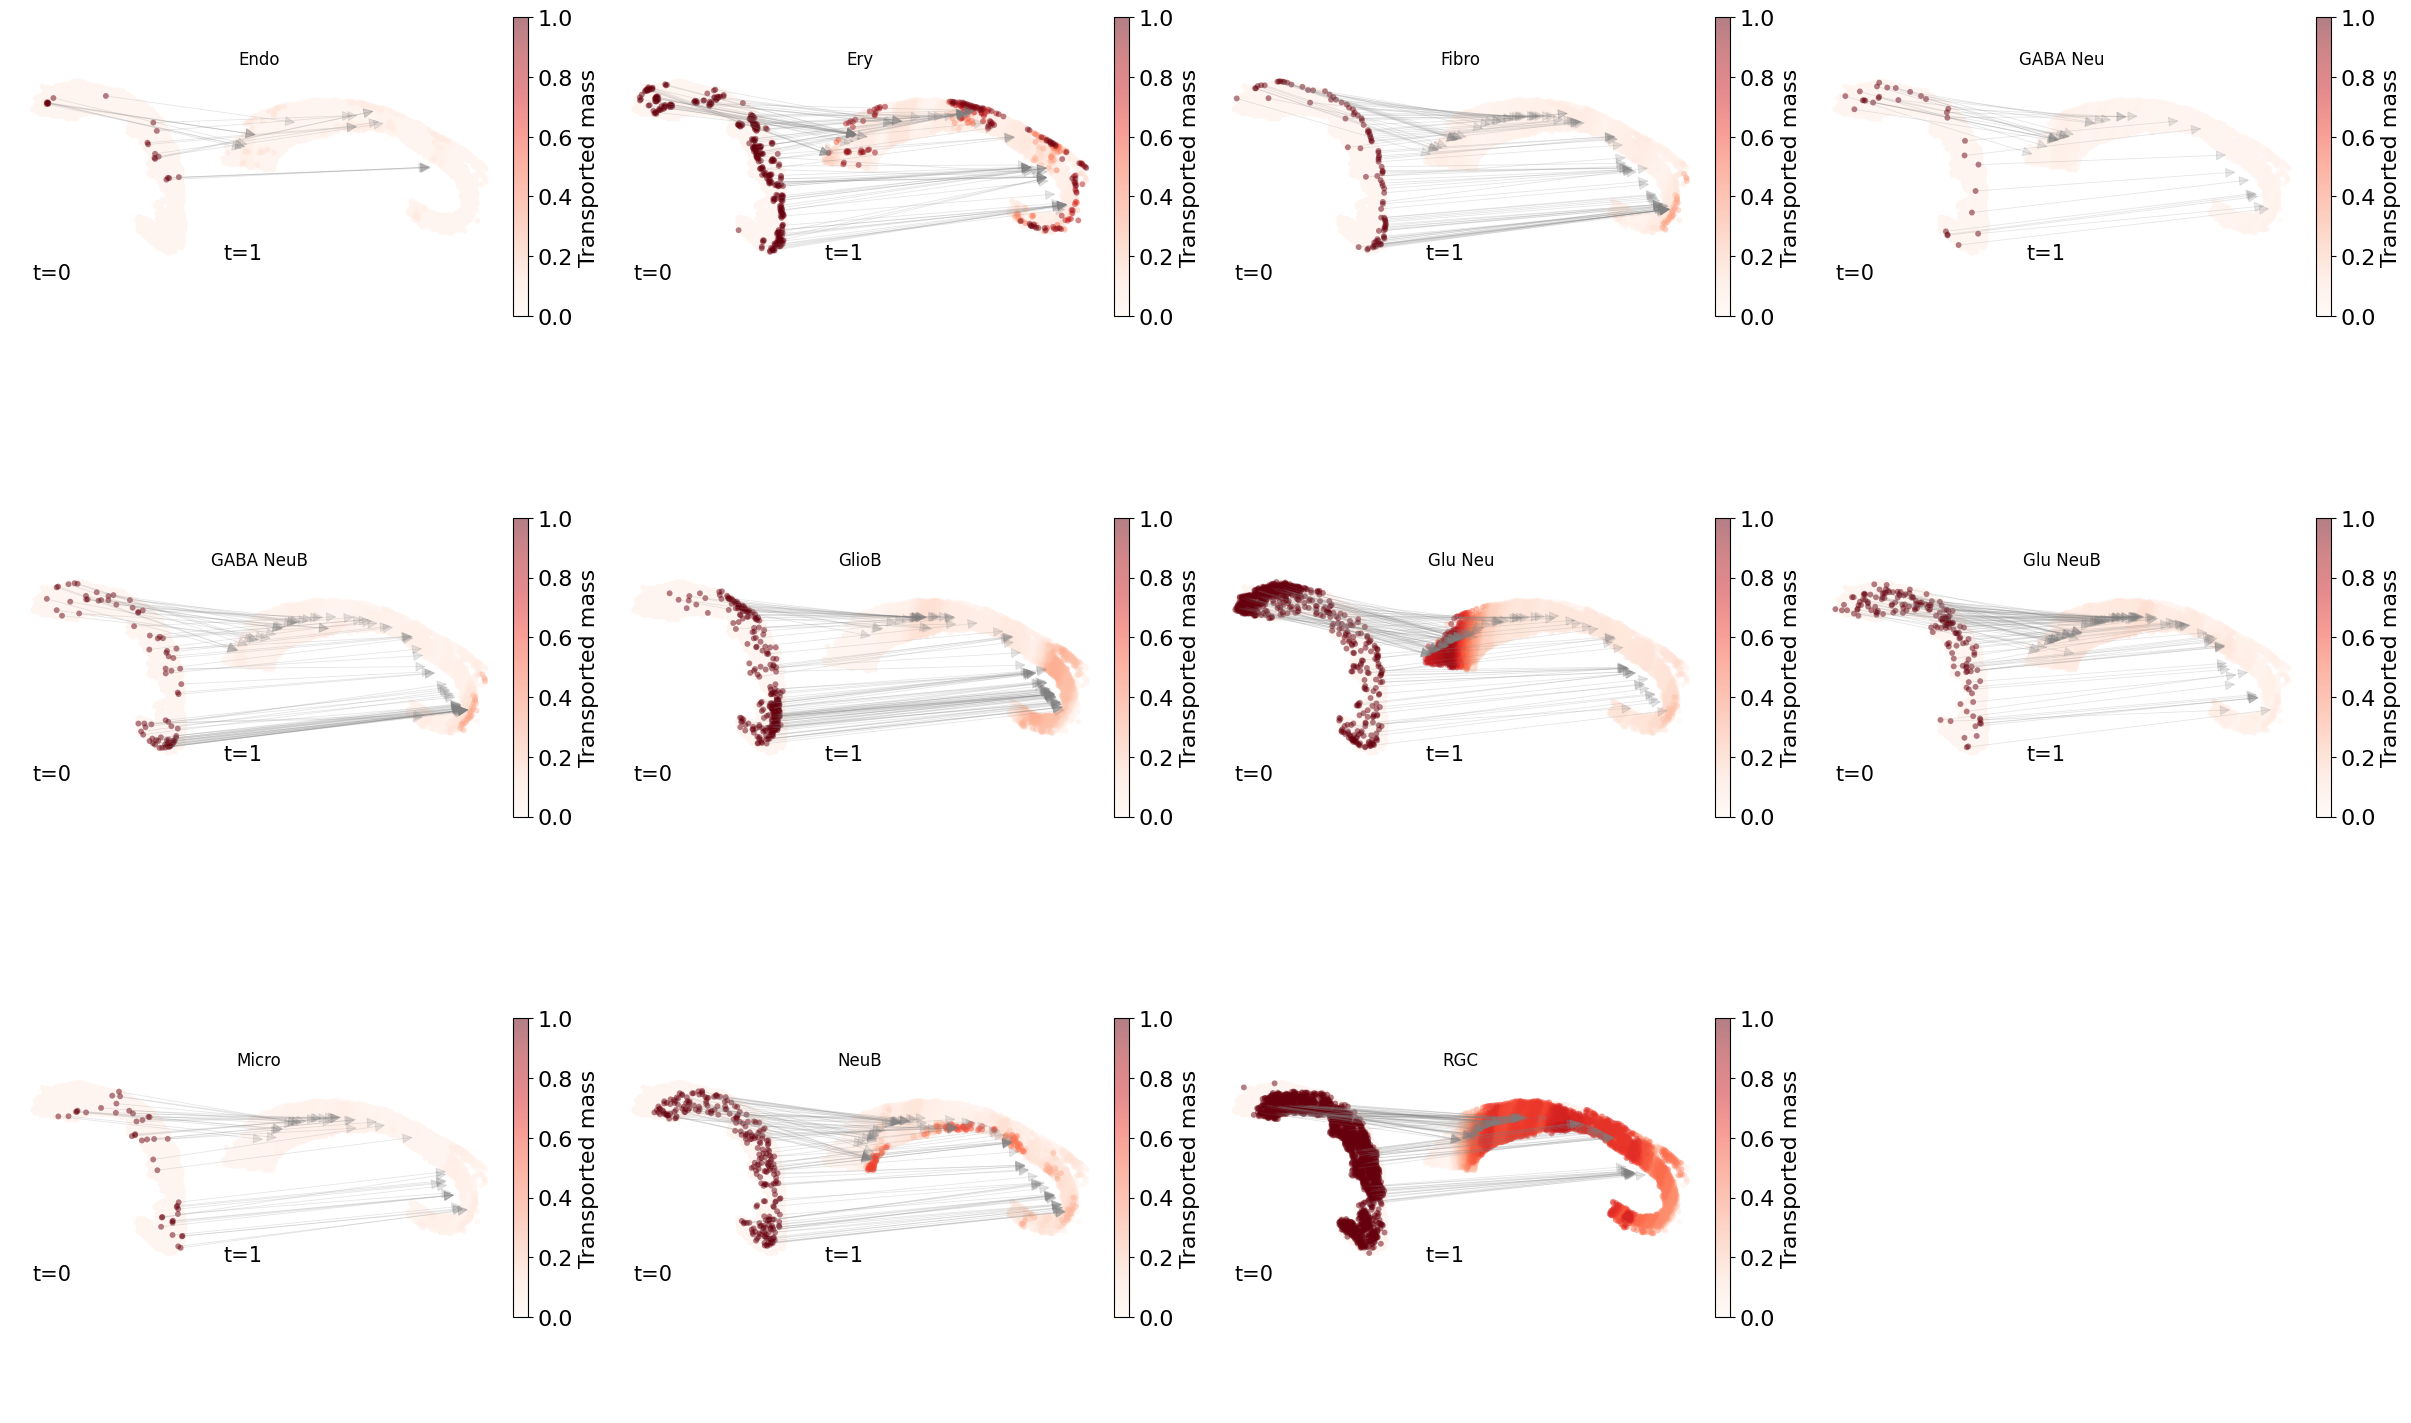

In [18]:
import math

pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]


cell_types = list(adata_insamp[0].obs["annotation"].unique())
cell_types = sorted(cell_types)   
n = len(cell_types)

ncols = 4                         
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6 * ncols, 5 * nrows),   
    constrained_layout=True
)


axes = np.asarray(axes).reshape(-1)


for i, cell_type in enumerate(cell_types):
    ax = axes[i]

    
    fig_i, ax_i, masses = plot_mass_transport_heatmap(
        adata_insamp,
        V,
        pi_dense,
        t_start=0,
        t_end=1,
        source_celltype=cell_type,
        celltype_obs_key="annotation",
        source_mass_source="obs",
        y_gap=4800,
        y_scale=1.0,
        show_edges=True,
        n_sources_show = 100,
        alpha=0.5,
        cmap="Reds",
        edge_alpha=0.2,
        ax=ax,          
        fig=fig,        
       
    )

    ax.set_title(str(cell_type), fontsize=12)

# --- 4) Turn off any unused axes (if grid > n)
for j in range(n, len(axes)):
    axes[j].axis("off")

# Now try an interpolation between the first and last slices

In [23]:
n_time = 3
import importlib
import impute_frlc

# from impute_frlc import mccann_interpolate
from impute import impute_slice_fgw_barycenter, _prepare_fgw_inputs

V, pi, _ = solve_V_all_slices(
            [adata_insamp[0],adata_insamp[-1]], pd_B,  #lam=0, mu=0,
            k=10,
            step_rate='automatic', one_step=True, ot_solver='low_rank'
        )

X1 = np.vstack([adata_insamp[-1].obs['x'], adata_insamp[-1].obs['y']]).T
X0 = np.vstack([adata_insamp[0].obs['x'],  adata_insamp[0].obs['y']]).T
Y1 = V[-1]
Y0 = V[0]

X_aligned_list = []
X_true_list    = []
Y_bar_list     = []
Y_true_list    = []

X_true        = np.vstack([adata_insamp[1].obs['x'], adata_insamp[1].obs['y']]).T



Yb = Cb = None
X_aligned_list, Y_bar_list = [], []

for i in range(3):
    print(i)
    X_bar, Y_bar, C_bar, log = impute_slice_fgw_barycenter(
        X0, Y0, X1, Y1,
        t=0.25 * (i + 1),
        N_bary=3000,#adata_list[i+1].obs['x'].shape[0], 
        alpha=0.5,
        epsilon=0.01,
        tol = 1e-1,
        armijo=True,
        n_input = 1000,
        random_state=42,
    )


    X_aligned_list.append(align_by_rotation(X_bar, X_true))
    Y_bar_list.append(Y_bar)



lambda used = 7.234090e+02 (auto)
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
mu used = 6.862787e+02 (auto)
iter    0  f=2.534521e+08  rel_drop=8.092e-04  mean step=7.58e-06
iter   29  f=2.530893e+08  rel_drop=9.826e-06  mean step=6.79e-06
stopped after iteration # 29
final spatial/data ratio  = 5.597651e-03
final temporal/data ratio = 6.939236e-03
0
1
2


# To inspect a specific gene:

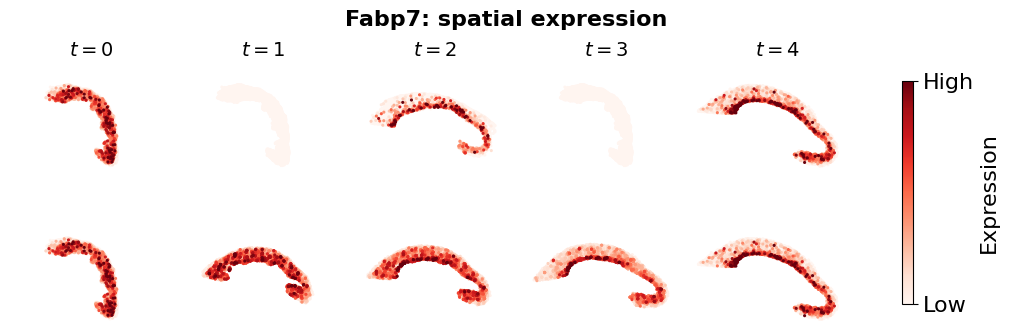

In [24]:
gene = 'Fabp7'


def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[0], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[1], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[2], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

import pandas as pd
genes = adata_insamp[0].var_names          # must match Y_bar_full_list column order
I = pd.DataFrame(np.eye(len(genes)), columns=genes)



rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Reds')

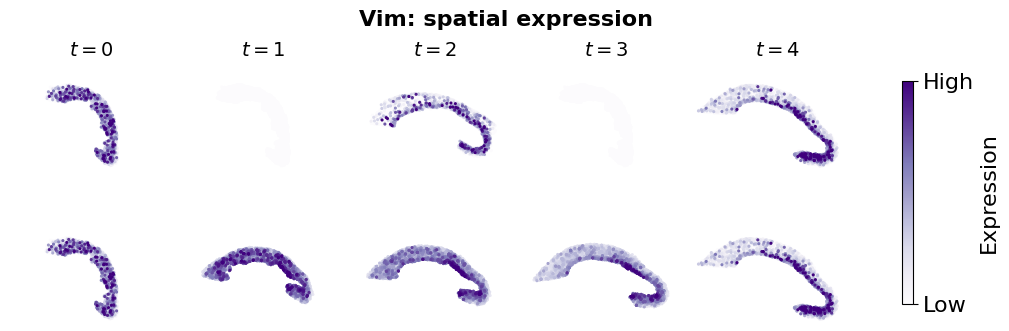

In [25]:
gene = 'Vim'

def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[0], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[1], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[2], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Purples')